# 使用神经网络识别手写数字(二分类)

## 问题描述

使用神经网络识别手写数字0和1，这是一个二分类任务，后续扩展成 0-9 的多分类任务。

## 数据集

首先加载本任务的数据集。
- 下面的 `load_data()` 函数将数据加载到变量 `X` 和 `y`。
  

- 数据集包含 1000 个手写数字训练样本 $^1$，这里仅使用数字 0 和 1。
    - 每个训练样本是一张 20 × 20 像素的数字灰度图像。
        - 每个像素由一个浮点数表示，表示该位置的灰度强度。
        - 将 20 × 20 的像素网格“展开”为一个 400 维向量。
        - 每个训练样本成为数据矩阵 `X` 中的一行。
        - 最终得到一个 1000 × 400 的矩阵 `X`，每一行都是一张手写数字图像的训练样本。

$$X = 
\left(\begin{array}{cc} 
--- (x^{(1)}) --- \\
--- (x^{(2)}) --- \\
\vdots \\ 
--- (x^{(m)}) --- 
\end{array}\right)$$

- 训练集的第二部分是一个 1000 × 1 的向量 `y`，包含训练集的标签。
    - 如果图像表示数字 `0`，则 `y = 0`；如果图像表示数字 `1`，则 `y = 1`。

$^1$<sub>这是 MNIST 手写数字数据集的一个子集 (http://yann.lecun.com/exdb/mnist/)</sub>


In [13]:
import numpy as np
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
import matplotlib.pyplot as plt

import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

In [14]:
def load_data():
    X = np.load('data/X.npy')
    y = np.load('data/y.npy')
    X = X[0:1000]
    y = y[0:1000]
    return X, y

X, y = load_data()

# 查看变量
print('The shape of X is: ' + str(X.shape))
print('The shape of y is: ' + str(y.shape))
print('The first element of X is:', X[0])
print('The first element of y is:', y[0, 0])
print('The last element of y is:', y[-1, 0])

The shape of X is: (1000, 400)
The shape of y is: (1000, 1)
The first element of X is: [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0

### 可视化数据

下面的单元从 X 中随机选择64行，将每行还原成 20×20 像素的灰度图像，并一起显示这些图像

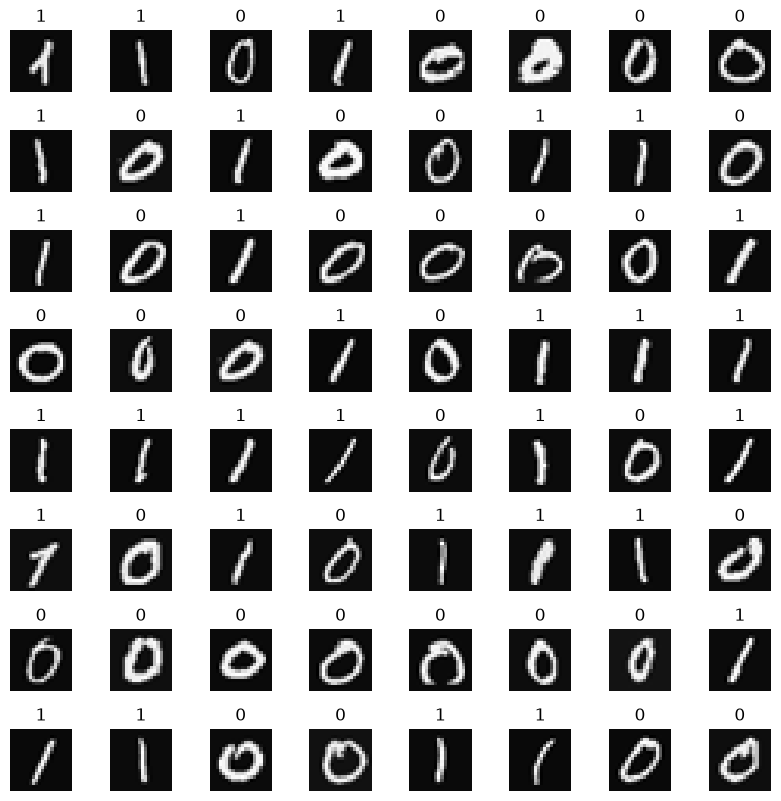

In [15]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# 无需修改此单元中的任何内容

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(8,8))
fig.tight_layout(pad=0.1)

for i,ax in enumerate(axes.flat):
    # 随机选择索引
    random_index = np.random.randint(m)
    
    # 选择随机索引对应的行，并
    # 调整图像形状
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # 显示图像
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # 在图像上方显示标签
    ax.set_title(y[random_index,0])
    ax.set_axis_off()

## 模型表示

本次实验使用的神经网络如下图所示。

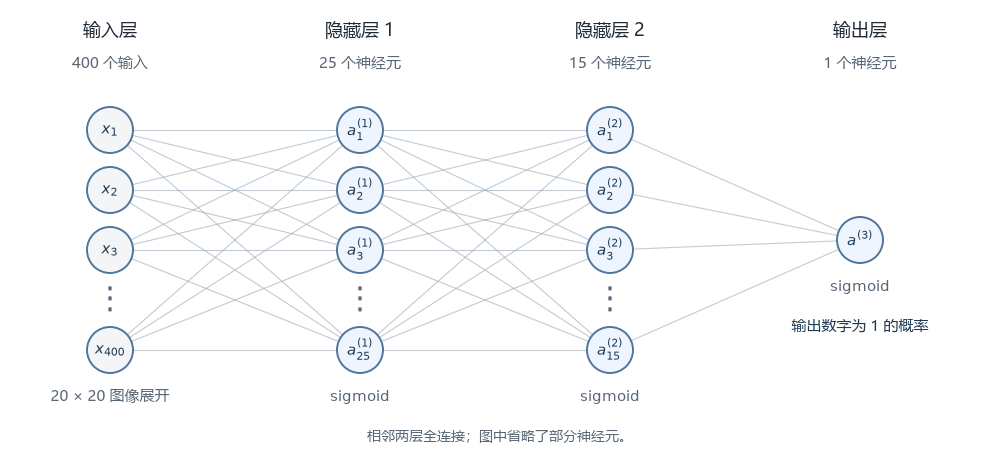

- 输入层：400 个输入，对应于 20×20 像素的灰度图像。
- 隐藏层：第一层有25个神经元，第二层15个
- 输出层：1个神经元，对应于二分类任务
- 激活函数：sigmoid
- 损失函数：交叉熵

因此，神经网络的参数为：
- 输入层到第一隐藏层的权重 $W^{(1)}$，大小为 $400 \times 25$
- 第一隐藏层到第二隐藏层的权重 $W^{(2)}$，大小为 $25 \times 15$
- 第二隐藏层到输出层的权重 $W^{(3)}$，大小为 $15 \times 1$
- 第一隐藏层的偏置 $b^{(1)}$，大小为 $25 \times 1$
- 第二隐藏层的偏置 $b^{(2)}$，大小为 $15 \times 1$



## TensorFlow 模型实现

首先使用 Sequential API 和 Keras Dense 层实现神经网络模型。


In [16]:
model = Sequential(
    [
        tf.keras.Input(shape=(400,)),
        Dense(25, activation='sigmoid'),
        Dense(15, activation='sigmoid'),
        Dense(1, activation='sigmoid')
    ], name = 'my_model'
)
model.summary()

Model: "my_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 25)             │        10,025 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 15)             │           390 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,431 (40.75 KB)

 Trainable params: 10,431 (40.75 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
[layer1, layer2, layer3] = model.layers
# 查看权重形状
W1,b1 = layer1.get_weights()
W2,b2 = layer2.get_weights()
W3,b3 = layer3.get_weights()
print(f"W1 shape = {W1.shape}, b1 shape = {b1.shape}")
print(f"W2 shape = {W2.shape}, b2 shape = {b2.shape}")
print(f"W3 shape = {W3.shape}, b3 shape = {b3.shape}")

W1 shape = (400, 25), b1 shape = (25,)
W2 shape = (25, 15), b2 shape = (15,)
W3 shape = (15, 1), b3 shape = (1,)


In [18]:
# 定义损失函数，并执行梯度下降，使模型权重拟合训练数据
model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
)

model.fit(
    X, y,
    epochs = 20
)

Epoch 1/20


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6021   
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4092 
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2602 
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1717 
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1226 
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0932 
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0741 
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0609 
Epoch 9/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0513 
Epoch 10/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0440 
Epoch 11/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0385 
Epoch 12/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0342 
Epoch 13/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0307 
Epoch 14/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0279 
Epoch 15/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0255 
Epoch 16/20
3

使用 Keras 的 `model.predict()` 函数来预测训练集的标签。

In [19]:
prediction = model.predict(X[0].reshape(1,400))  # 数字 0
print(f" predicting a zero: {prediction}")
prediction = model.predict(X[500].reshape(1,400))  # 数字 1
print(f" predicting a one:  {prediction}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
 predicting a zero: [[0.01293992]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
 predicting a one:  [[0.9879335]]


In [20]:
# 加入阈值
if prediction >= 0.5:
    yhat = 1
else:
    yhat = 0
print(f"prediction after threshold: {yhat}")

prediction after threshold: 1


下面对随机抽取的 64 个数字比较预测结果和标签

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━

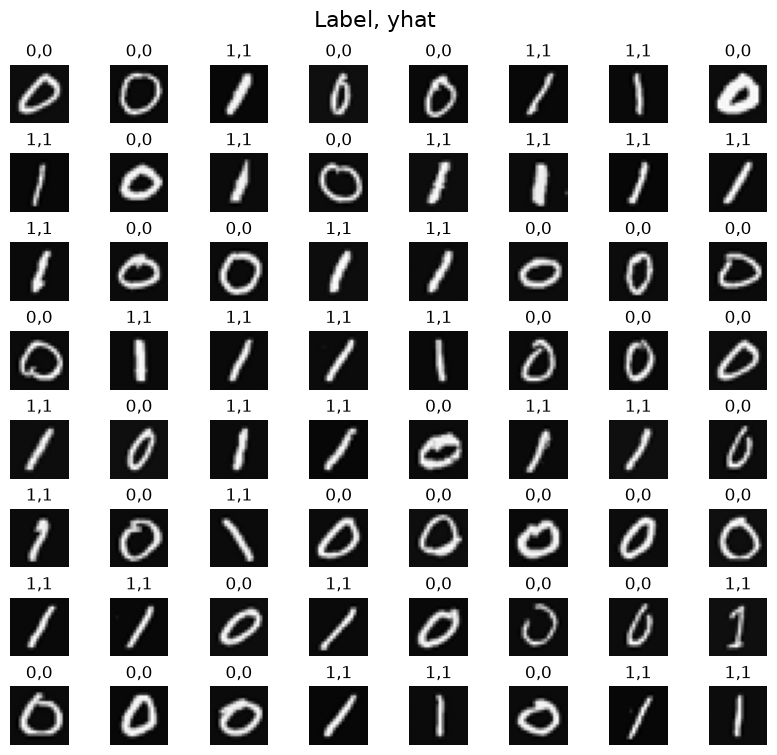

In [21]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# 无需修改此单元中的任何内容

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(8,8))
fig.tight_layout(pad=0.1,rect=[0, 0.03, 1, 0.92]) #[左, 下, 右, 上]

for i,ax in enumerate(axes.flat):
    # 随机选择索引
    random_index = np.random.randint(m)
    
    # 选择随机索引对应的行，并
    # 调整图像形状
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # 显示图像
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # 使用神经网络进行预测
    prediction = model.predict(X[random_index].reshape(1,400))
    if prediction >= 0.5:
        yhat = 1
    else:
        yhat = 0
    
    # 在图像上方显示标签
    ax.set_title(f"{y[random_index,0]},{yhat}")
    ax.set_axis_off()
fig.suptitle("Label, yhat", fontsize=16)
plt.show()

## NumPy 模型实现

也可以使用 NumPy 自行构建全连接层，再用它构建多层神经网络

首先编写全连接层子程序

In [22]:
def my_dense(a_in, W, b, g):
    """
    计算全连接层的输出
    参数：
      a_in (ndarray (n, )) : 数据，1 个样本 
      W    (ndarray (n,j)) : 权重矩阵，每个单元有 n 个特征，共 j 个单元
      b    (ndarray (j, )) : 偏置向量，j 个单元  
      g    激活函数（例如 sigmoid、ReLU 等）
    返回值
      a_out (ndarray (j,))  : j 个单元
    """
    units = W.shape[1]
    a_out = np.zeros(units)

    a_out = a_in @ W + b # 矩阵乘法
    a_out = g(a_out)

    return(a_out)


In [23]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# 快速检查
x_tst = 0.1*np.arange(1,3,1).reshape(2,)  # (1 个样本，2 个特征)
W_tst = 0.1*np.arange(1,7,1).reshape(2,3) # (2 个输入特征，3 个输出特征)
b_tst = 0.1*np.arange(1,4,1).reshape(3,)  # (3 个特征)
A_tst = my_dense(x_tst, W_tst, b_tst, sigmoid)
print(A_tst)

[0.54735762 0.57932425 0.61063923]


然后使用`my_dense`函数构建神经网络，最终返回的是输出层的输出

In [25]:
def my_sequential(X, W1, b1, W2, b2, W3, b3, g):
    a1 = my_dense(X, W1, b1, g)
    a2 = my_dense(a1, W2, b2, g)
    a3 = my_dense(a2, W3, b3, g)
    return(a3)

我们从 TensorFlow 模型中获取权重和偏置，并使用 NumPy 模型进行预测

In [29]:
W1_tmp,b1_tmp = layer1.get_weights()
W2_tmp,b2_tmp = layer2.get_weights()
W3_tmp,b3_tmp = layer3.get_weights()

# 进行预测
prediction = my_sequential(X[0], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp, sigmoid)
if prediction >= 0.5:
    yhat = 1
else:
    yhat = 0
print( "yhat = ", yhat, " label= ", y[0,0])
prediction = my_sequential(X[500], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp, sigmoid )
if prediction >= 0.5:
    yhat = 1
else:
    yhat = 0
print( "yhat = ", yhat, " label= ", y[500,0])

yhat =  0  label=  0
yhat =  1  label=  1


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━

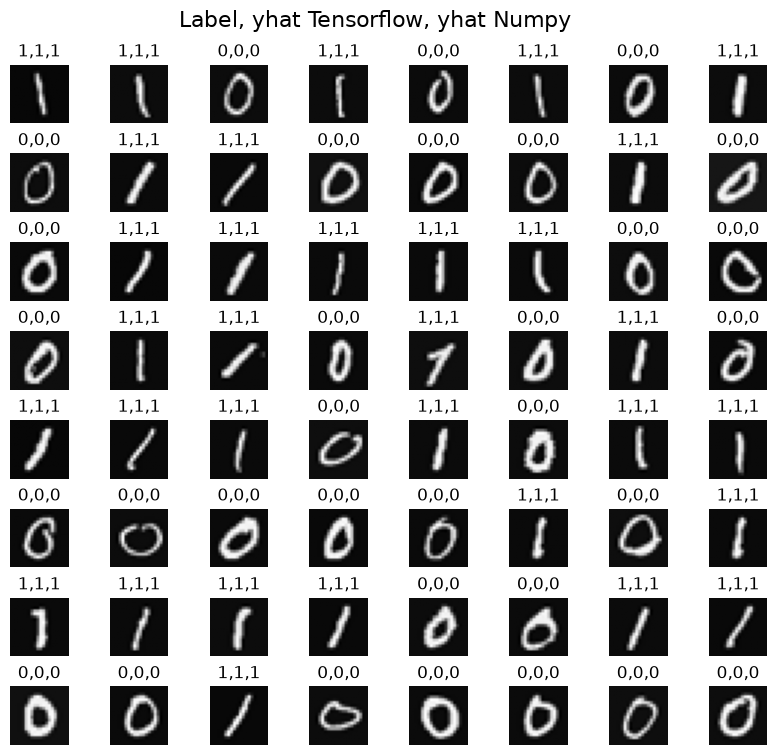

In [31]:
# 查看两个模型的预测结果
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# 无需修改此单元中的任何内容

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(8,8))
fig.tight_layout(pad=0.1,rect=[0, 0.03, 1, 0.92]) #[左, 下, 右, 上]

for i,ax in enumerate(axes.flat):
    # 随机选择索引
    random_index = np.random.randint(m)
    
    # 选择随机索引对应的行，并
    # 调整图像形状
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # 显示图像
    ax.imshow(X_random_reshaped, cmap='gray')

    # 预测结果是单元素数组，先用 .item() 取出数值，再按阈值分类。
    # 使用 NumPy 实现的神经网络进行预测
    my_prediction = my_sequential(X[random_index], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp, sigmoid )
    my_yhat = int(my_prediction.item() >= 0.5)

    # 使用 TensorFlow 实现的神经网络进行预测
    tf_prediction = model.predict(X[random_index].reshape(1,400))
    tf_yhat = int(tf_prediction.item() >= 0.5)
    
    # 在图像上方显示标签
    ax.set_title(f"{y[random_index,0]},{tf_yhat},{my_yhat}")
    ax.set_axis_off() 
fig.suptitle("Label, yhat Tensorflow, yhat Numpy", fontsize=16)
plt.show()